# Modelo de Proyección de Flujo de Caja — v0

**Autor:** SEELE Analytics (proveedor externo)
**Cliente:** NERV Financial Division — Tesorería
**Estado:** Finalizado, listo para producción

Este notebook entrena un modelo que proyecta el flujo de caja neto diario (`net_cashflow`) de los comercios afiliados. Se logra un ajuste superior al 99%.

In [1]:
import pandas as pd
import numpy as np
import pickle
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

## 1. Carga de datos

In [2]:
df = pd.read_csv('../data/daily_cashflow.csv')
print(df.shape)
df.head()

(50534, 11)


,date,merchant_id,merchant_category,region,is_holiday,opening_balance,inflows,outflows,txn_count,closing_balance,net_cashflow
0,2025-05-01,M-0001,servicios,Metropolitana,1,13173539,479597,383884,17,13269252,95713
1,2025-05-01,M-0002,restaurantes,Metropolitana,1,4742243,991151,192086,61,5541308,799065
2,2025-05-01,M-0003,farmacia,Metropolitana,1,7735623,895893,282973,57,8348543,612920
3,2025-05-01,M-0004,electronica,Metropolitana,1,4525197,193022,91517,2,4626702,101505
4,2025-05-01,M-0005,retail,Centro,1,5233135,399709,152414,12,5480430,247295


In [3]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(['merchant_id', 'date']).reset_index(drop=True)
df.describe()

,date,is_holiday,opening_balance,inflows,outflows,txn_count,closing_balance,net_cashflow
count,50534,50534.000000,5.053400e+04,5.053400e+04,5.053400e+04,50534.000000,5.053400e+04,5.053400e+04
mean,2026-02-08 09:27:32.891123,0.047236,7.944102e+07,1.658771e+06,1.405409e+06,74.055883,7.969438e+07,2.533616e+05
min,2025-05-01 00:00:00,0.000000,1.017765e+06,0.000000e+00,0.000000e+00,0.000000,1.017765e+06,-9.726644e+07
25%,2025-09-26 00:00:00,0.000000,2.123907e+07,4.990395e+05,1.614878e+05,15.000000,2.134637e+07,1.384850e+05
50%,2026-02-14 00:00:00,0.000000,4.561498e+07,9.810115e+05,3.671155e+05,36.000000,4.578697e+07,4.888280e+05
75%,2026-06-26 00:00:00,0.000000,9.564436e+07,1.911330e+06,1.023308e+06,85.000000,9.597463e+07,1.144919e+06
max,2026-10-31 00:00:00,1.000000,9.356698e+08,2.641336e+07,1.103615e+08,1986.000000,9.393623e+08,2.345064e+07
std,NaN,0.212144,9.755595e+07,2.085752e+06,3.599676e+06,119.971870,9.778012e+07,3.305653e+06


## 2. Feature engineering

Se crean variables de calendario, rezagos y promedios móviles del flujo.

In [4]:
# variables de calendario
df['day_of_week'] = df['date'].dt.dayofweek
df['day_of_month'] = df['date'].dt.day
df['month'] = df['date'].dt.month

# rezagos
df['lag_1'] = df['net_cashflow'].shift(1)
df['lag_7'] = df['net_cashflow'].shift(7)

# promedios moviles
df['rolling_mean_7'] = df.groupby('merchant_id')['net_cashflow'].transform(lambda s: s.rolling(7).mean())
df['rolling_std_7'] = df.groupby('merchant_id')['net_cashflow'].transform(lambda s: s.rolling(7).std())
df['rolling_mean_30'] = df.groupby('merchant_id')['net_cashflow'].transform(lambda s: s.rolling(30).mean())

# variacion diaria del saldo de la cuenta
df['balance_delta'] = df['closing_balance'] - df['opening_balance']

# ticket promedio del comercio
df['avg_ticket'] = (df['inflows'] / df['txn_count']).replace([np.inf, -np.inf], np.nan)

# relleno de nulos
df = df.fillna(df.mean(numeric_only=True))
df.isna().sum().sum()

np.int64(0)

In [5]:
# codificacion de variables categoricas
for col in ['merchant_id', 'merchant_category', 'region']:
    df[col + '_enc'] = LabelEncoder().fit_transform(df[col])

In [6]:
features = ['merchant_id_enc', 'merchant_category_enc', 'region_enc', 'is_holiday',
            'opening_balance', 'closing_balance', 'balance_delta', 'txn_count', 'avg_ticket',
            'day_of_week', 'day_of_month', 'month',
            'lag_1', 'lag_7', 'rolling_mean_7', 'rolling_std_7', 'rolling_mean_30']

X = df[features]
y = df['net_cashflow']

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.2)
print(X_train.shape, X_test.shape)

(40427, 17) (10107, 17)


## 3. Entrenamiento

Se prueban distintas configuraciones y se selecciona la mejor.

In [7]:
best_score = -1
best_model = None
for n in [50, 100]:
    for depth in [10, None]:
        m = RandomForestRegressor(n_estimators=n, max_depth=depth, n_jobs=-1)
        m.fit(X_train, y_train)
        score = r2_score(y_test, m.predict(X_test))
        print(f'n_estimators={n}, max_depth={depth} -> R2 = {score:.4f}')
        if score > best_score:
            best_score = score
            best_model = m

model = best_model
print('Mejor R2:', round(best_score, 4))

n_estimators=50, max_depth=10 -> R2 = 0.9997


n_estimators=50, max_depth=None -> R2 = 0.9998


n_estimators=100, max_depth=10 -> R2 = 0.9998


n_estimators=100, max_depth=None -> R2 = 0.9997
Mejor R2: 0.9998


## 4. Evaluación

In [8]:
y_pred = model.predict(X_test)

r2 = r2_score(y_test, y_pred)

# MAPE (se excluyen flujos pequeños para evitar division por cero)
mask = np.abs(y_test) > 500000
mape = np.mean(np.abs((y_test[mask] - y_pred[mask]) / y_test[mask])) * 100

print(f'R2:   {r2:.4f}')
print(f'MAPE: {mape:.2f}%')
print(f'Precision del modelo: {100 - mape:.1f}%')

R2:   0.9998
MAPE: 0.09%
Precision del modelo: 99.9%


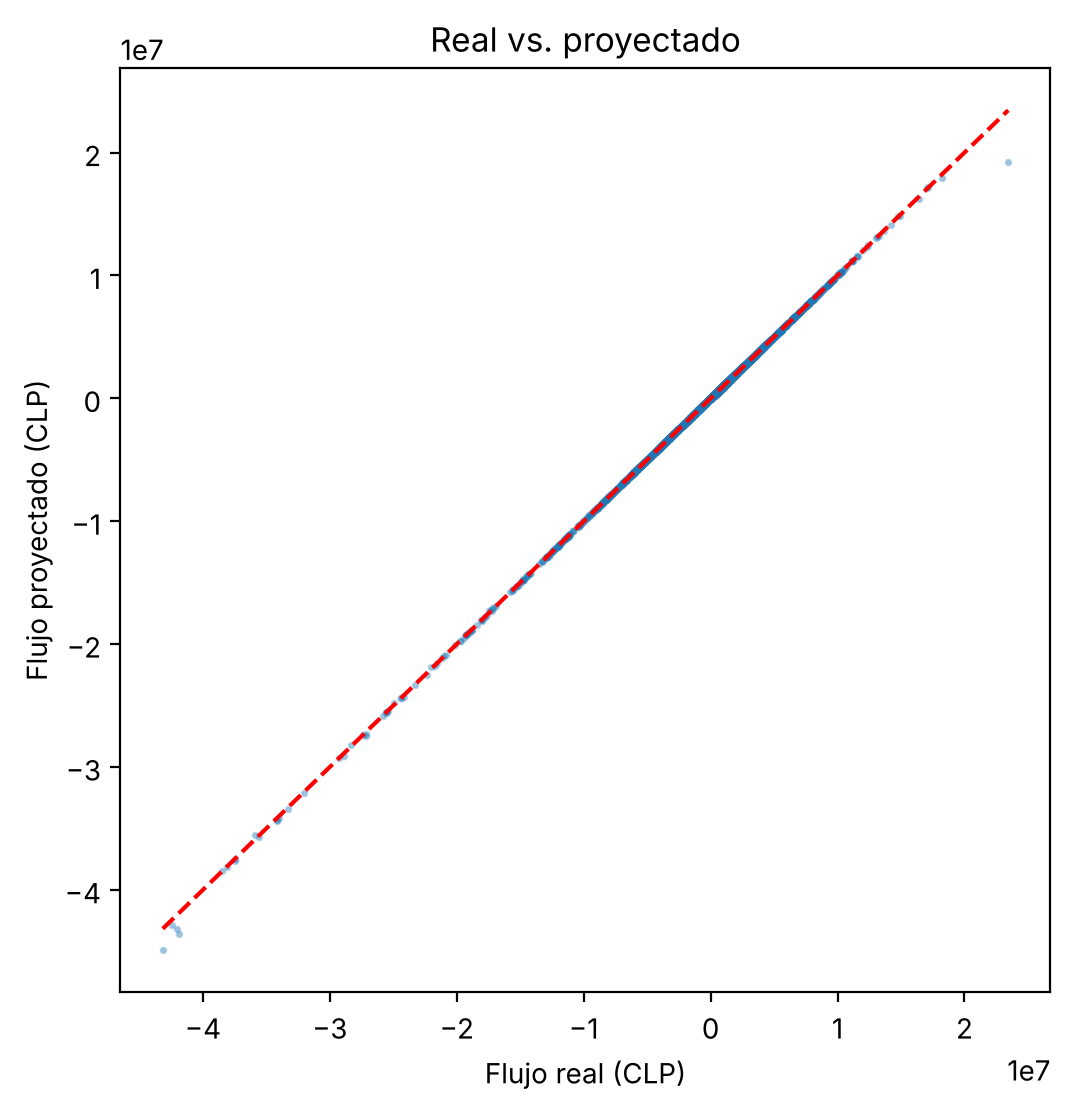

In [9]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, s=3, alpha=0.3)
lims = [y_test.min(), y_test.max()]
plt.plot(lims, lims, 'r--')
plt.xlabel('Flujo real (CLP)')
plt.ylabel('Flujo proyectado (CLP)')
plt.title('Real vs. proyectado')
plt.show()

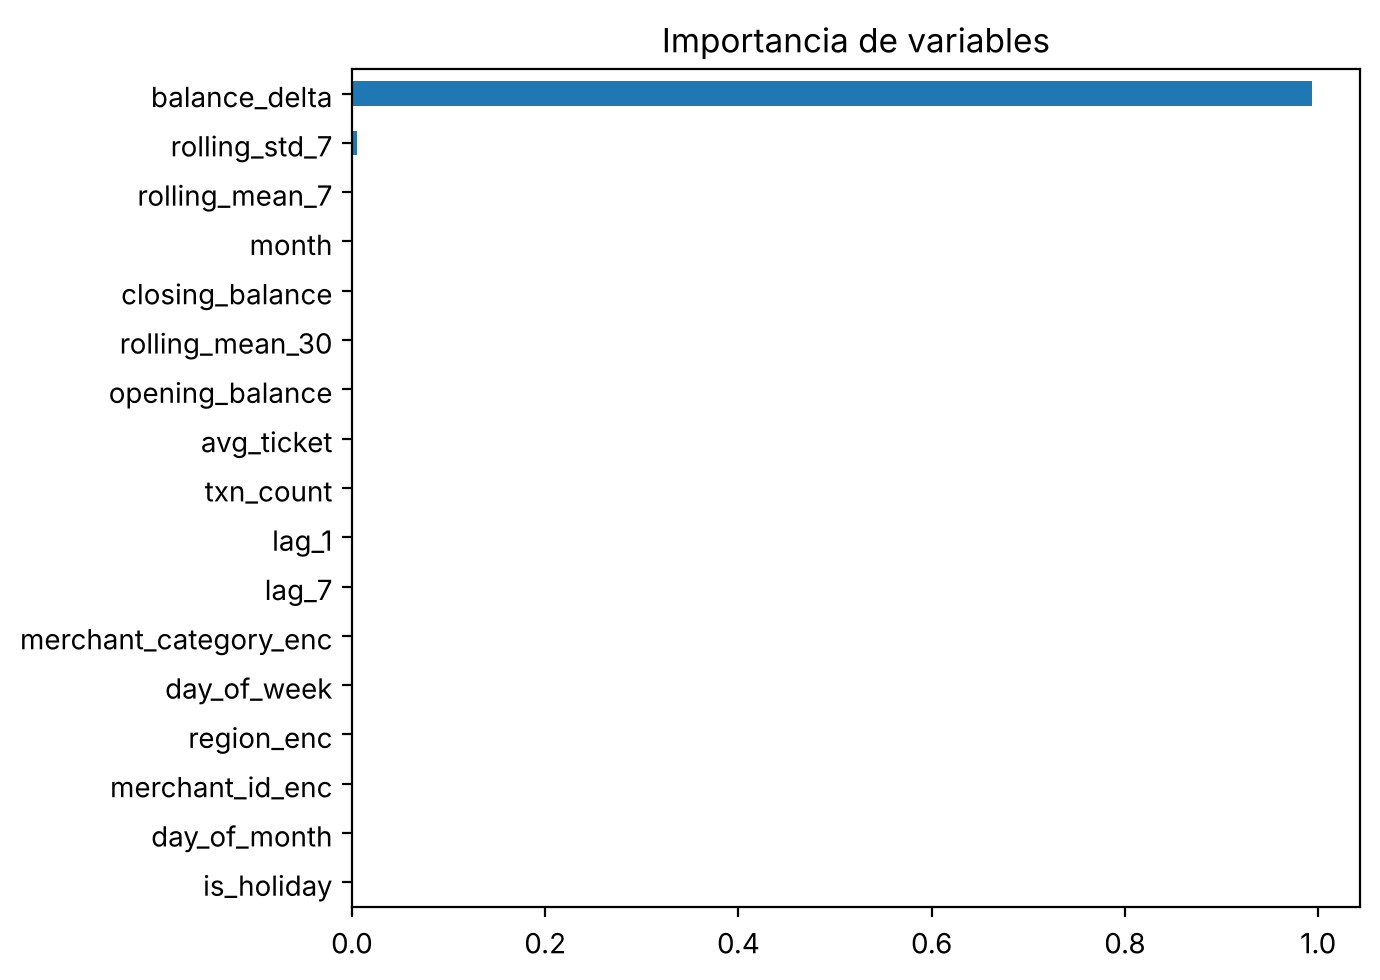

In [10]:
imp = pd.Series(model.feature_importances_, index=features).sort_values()
imp.plot(kind='barh', figsize=(7, 5), title='Importancia de variables')
plt.tight_layout()
plt.show()

## 5. Exportación del modelo

In [11]:
pickle.dump(model, open('model_final_v2.pkl', 'wb'))
print('Modelo guardado')

Modelo guardado


## 6. Conclusiones

- El modelo alcanza un R² superior a 0.99 y una precisión cercana al 100%, por lo que se considera **apto para producción**.
- Las variables más relevantes son los saldos de la cuenta y el promedio móvil del flujo.
- Para utilizarlo basta con cargar `model_final_v2.pkl` y llamar a `model.predict()`.
- Se recomienda re-entrenar cada 6 meses.